# SFH posterior from S-PLUS colours (part 3)

A normalizing flow (trained by `train_ml_model.py` on the 3090) gives each galaxy a posterior over its SFH: 15 bin mass fractions, metallicity (Z_fin, hence every bin), dust, masses and redshift. Inputs are the 11 colours against r, the r magnitude (only for the absolute masses), and z_obs with its uncertainty (0 for spectroscopic redshifts).

**Inputs:** `ml_runs/mlp/`, `ml_runs/cnn/`, `synthetic_validation.parquet`, `synthetic_test.parquet`, `training_set.parquet` (prior draws), `spectroscopic_reference.csv`, `dr3_corrected.csv`.
**Outputs:** `ml_evaluation_summary.csv`, `ml_sfh_catalogue.parquet`.
**Run:** top to bottom with the *Inference4ETGs (MultiNest)* kernel. Sections marked **LOCKED** run only with `RUN_LOCKED_TEST = True`, once, after the embedding is chosen: they use the synthetic test set and the reference set's test half.

Posterior samples for the same seed differ between CUDA and CPU (`DEVICE`): numbers are reproducible per device, not across devices.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import torch

import ml_data
import ml_evaluation as ev
import ml_networks
import synthetic_model as sm

RUN_LOCKED_TEST = False            # set True once, for the final report
RUN_DIRECTORIES = {"mlp": "ml_runs/mlp", "cnn": "ml_runs/cnn"}
VALIDATION_FILE = "synthetic_validation.parquet"
TEST_FILE = "synthetic_test.parquet"
TRAINING_FILE = "training_set.parquet"
REFERENCE_FILE = "spectroscopic_reference.csv"
SPLUS_FILE = "dr3_corrected.csv"
SUMMARY_FILE = "ml_evaluation_summary.csv"
CATALOGUE_FILE = "ml_sfh_catalogue.parquet"

N_POSTERIOR_SAMPLES = 1000         # per galaxy for evaluation
N_CATALOGUE_SAMPLES = 500          # per galaxy for the DR3 catalogue
SAMPLING_SEED = 7
VALIDATION_SEEDS = {"spectroscopic": 100, "photometric": 101}   # same copies as training used
TEST_SEEDS = {"spectroscopic": 200, "photometric": 201}
KEY_LABELS = ["mw_age", "Z_fin", "f_young", "f_mid", "f_old", "log_mstar", "log_sfr"]
REFERENCE_LABELS = ["mw_age", "Z_fin", "f_old", "log_mstar"]
PRIOR_WINDOW_DZ = 0.05             # prior draws within this redshift of a galaxy define its prior width
MIN_PROB_GALAXY = 0.8
PASSIVE_SSFR_LIMIT = -11            # [log10 yr^-1] spectral sSFR below this = passive galaxy
PRIOR_SEED = 11                     # brightness offsets of the prior draws
N_JOBS = 11
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # flow sampling is autoregressive: slow on CPU

runs = {}
for name, directory in RUN_DIRECTORIES.items():
    runs[name] = ml_networks.load_run(directory, device=DEVICE)

BAGPIPES: Generating IGM absorption table.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


## 1. Training and model choice

Both embeddings saw the same data, budget and seeds. The choice uses the validation set only: lower loss, then coverage closer to nominal.

,best_validation_loss,mean_coverage_error
embedding,,
cnn,-44.6121,0.0688
mlp,-65.9779,0.0612


Chosen embedding: mlp


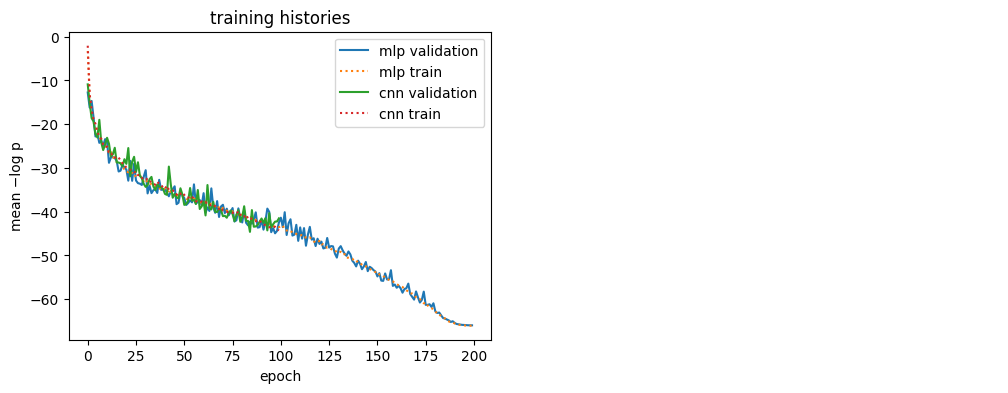

In [2]:
GALAXY_CHUNK = 500                 # galaxies decoded at once: all 16k x 1000 samples x 58 labels would need ~8 GB


def labelled_posteriors(run, observations, n_samples, seed, labels=None):
    """Decoded posterior labels for every valid galaxy: dict label -> array (n_valid, n_samples).

    labels: names to keep (default all 58). Decoding runs in galaxy chunks, so only the kept labels
    are ever held for the whole set.
    """
    estimator, _, standardisers = run
    valid = observations["valid"]
    if not valid.any():
        raise ValueError("no valid galaxy (every galaxy lacks a detected r band or a brightness donor): "
                         "nothing to predict")
    flat = observations["flat"][valid]
    banded = observations["banded"][valid]
    n_galaxies = len(flat)

    posteriors = {}
    for chunk_start in range(0, n_galaxies, GALAXY_CHUNK):
        chunk = slice(chunk_start, chunk_start + GALAXY_CHUNK)
        theta = ml_networks.posterior_samples(estimator, standardisers, flat[chunk], banded[chunk],
                                              n_samples, seed + chunk_start, DEVICE)
        n_chunk = theta.shape[0]
        decoded = ml_data.decode_samples(theta.reshape(-1, ml_data.N_TARGETS))
        for column in decoded.columns:
            if labels is not None and column not in labels:
                continue
            if column not in posteriors:
                posteriors[column] = np.empty((n_galaxies, n_samples))
            posteriors[column][chunk] = decoded[column].to_numpy().reshape(n_chunk, n_samples)
    truths = ml_data.decode_samples(observations["targets"][valid])
    return posteriors, truths


validation_table = pd.read_parquet(VALIDATION_FILE)
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
choice_rows = []
for name, run in runs.items():
    history = pd.read_csv(f"{RUN_DIRECTORIES[name]}/{ml_networks.HISTORY_FILE}")
    axes[0].plot(history["epoch"], history["validation_loss"], label=f"{name} validation")
    axes[0].plot(history["epoch"], history["train_loss"], ls=":", label=f"{name} train")
    for mode, seed in VALIDATION_SEEDS.items():
        observations = ml_data.validation_observations(validation_table, mode, np.random.default_rng(seed))
        posteriors, truths = labelled_posteriors(run, observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED, KEY_LABELS)
        for label in KEY_LABELS:
            coverage = ev.coverage_curve(posteriors[label], truths[label].to_numpy(), [0.68, 0.95])
            choice_rows.append({"embedding": name, "mode": mode, "label": label,
                                "coverage_68": coverage[0], "coverage_95": coverage[1],
                                "best_validation_loss": history["validation_loss"].min()})
axes[0].set(xlabel="epoch", ylabel="mean −log p", title="training histories")
axes[0].legend()
choice = pd.DataFrame(choice_rows)
choice["coverage_error"] = np.abs(choice["coverage_68"] - 0.68) + np.abs(choice["coverage_95"] - 0.95)
by_embedding = choice.groupby("embedding").agg(best_validation_loss=("best_validation_loss", "first"),
                                               mean_coverage_error=("coverage_error", "mean"))
display(by_embedding.round(4))
CHOSEN = by_embedding.sort_values(["best_validation_loss", "mean_coverage_error"]).index[0]
print(f"Chosen embedding: {CHOSEN}")
axes[1].axis("off")
plt.show()

## 2. Calibration, accuracy and information per bin (LOCKED: synthetic test set)

For each redshift mode, the left panel is the coverage curve of the key labels (a calibrated posterior lies on the diagonal) and the right panel the histogram of the rank of the truth among the posterior samples (flat means calibrated, U-shaped means too narrow). The table gives coverage, bias, NMAD and posterior/prior width for every label, including each age bin.

In [3]:
def mass_rescaled_prior(prior_table, catalogue, seed):
    """Prior draws sorted by redshift, with the mass-like labels at observed brightness.

    Why: training_set.parquet holds models at a fixed mass; an observed galaxy has the mass of its
    brightness (sm.scale_to_observed_r, as in training), so the prior width of log_mstar is ~1 dex, not 0.08.
    Inputs: prior_table: training_set.parquet; catalogue: DataFrame with r_auto and zml of DR3 galaxies;
            seed: for the brightness donors. Returns: DataFrame without rows lacking a donor, sorted by redshift.
    """
    offsets = sm.scale_to_observed_r(prior_table[sm.BANDS].to_numpy(dtype=float),
                                     prior_table["redshift"].to_numpy(dtype=float),
                                     catalogue["r_auto"].to_numpy(), catalogue["zml"].to_numpy(),
                                     np.random.default_rng(seed))[1]
    rescaled = sm.rescale_mass_labels(prior_table, offsets)
    return rescaled[np.isfinite(offsets)].sort_values("redshift").reset_index(drop=True)


def windowed_width_ratio(posterior, prior_table, label, true_redshift):
    """Posterior/prior width of a label, the prior taken within PRIOR_WINDOW_DZ of each galaxy's redshift."""
    prior_widths = ev.windowed_prior_widths(prior_table["redshift"].to_numpy(), prior_table[label].to_numpy(),
                                            true_redshift, PRIOR_WINDOW_DZ)
    return ev.width_ratio(posterior, None, prior_widths=prior_widths)


if RUN_LOCKED_TEST:
    test_table = pd.read_parquet(TEST_FILE)
    catalogue = pd.read_csv(SPLUS_FILE, usecols=["PROB_GAL", "r_auto", "zml"])
    catalogue = catalogue[catalogue["PROB_GAL"] > MIN_PROB_GALAXY]
    prior_table = mass_rescaled_prior(pd.read_parquet(TRAINING_FILE), catalogue, PRIOR_SEED)
    summary_rows = []
    bin_labels = []
    for bin_index in range(ml_data.N_FRACTION_BINS):
        bin_labels.append(f"frac_bin_{bin_index:02d}")
    for mode, seed in TEST_SEEDS.items():
        observations = ml_data.validation_observations(test_table, mode, np.random.default_rng(seed))
        posteriors, truths = labelled_posteriors(runs[CHOSEN], observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED,
                                                 KEY_LABELS + bin_labels)
        figure, axes = plt.subplots(1, 2, figsize=(12, 5))
        for label in KEY_LABELS + bin_labels:
            truth = truths[label].to_numpy()
            coverage = ev.coverage_curve(posteriors[label], truth)
            bias, nmad = ev.bias_and_nmad(np.nanmedian(posteriors[label], axis=1), truth)
            ratio = windowed_width_ratio(posteriors[label], prior_table, label, truths["redshift"].to_numpy())
            summary_rows.append({"section": "synthetic_test", "mode": mode, "label": label,
                                 "coverage_68": ev.coverage_curve(posteriors[label], truth, [0.68])[0],
                                 "coverage_95": ev.coverage_curve(posteriors[label], truth, [0.95])[0],
                                 "bias": bias, "nmad": nmad, "width_ratio": ratio})
            if label in KEY_LABELS:
                axes[0].plot(ev.NOMINAL_LEVELS, coverage, marker="o", label=label)
                axes[1].hist(ev.truth_ranks(posteriors[label], truth), bins=20, histtype="step", label=label)
        axes[0].plot([0, 1], [0, 1], color="black", lw=1)
        axes[0].set(xlabel="nominal coverage", ylabel="empirical coverage", title=f"{mode} redshift")
        axes[1].set(xlabel="rank of truth", ylabel="galaxies")
        axes[0].legend(fontsize=8)
        plt.show()
    summary = pd.DataFrame(summary_rows)
    display(summary.round(3))
else:
    print("synthetic test evaluation: skipped (locked)")

synthetic test evaluation: skipped (locked)


In [4]:
if RUN_LOCKED_TEST:
    # Information per age bin: posterior width / prior width (1 = the colours say nothing about that bin)
    spectroscopic_rows = summary[(summary["mode"] == "spectroscopic") & summary["label"].str.startswith("frac_bin_")]
    figure, axis = plt.subplots(figsize=(8, 4))
    axis.plot(range(ml_data.N_FRACTION_BINS), spectroscopic_rows["width_ratio"], marker="o")
    axis.axhline(1, color="grey", ls=":")
    axis.set_xticks(range(ml_data.N_FRACTION_BINS))
    axis.set_xticklabels([f"{centre:g}" for centre in sm.AGE_BIN_CENTRES[:ml_data.N_FRACTION_BINS]], rotation=60)
    axis.set(xlabel="bin centre [Gyr ago]", ylabel="posterior / prior 68% width",
             title="information per age bin (1 = prior only)")
    plt.show()

    # Accuracy against brightness, spectroscopic mode (the loop above ended on the photometric posteriors)
    spectroscopic_rng = np.random.default_rng(TEST_SEEDS["spectroscopic"])
    observations = ml_data.validation_observations(test_table, "spectroscopic", spectroscopic_rng)
    posteriors, truths = labelled_posteriors(runs[CHOSEN], observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED,
                                             ["mw_age", "log_mstar"])
    r_magnitude = observations["flat"][observations["valid"], ml_data.SCALAR_INPUT_SLICE.start]
    r_quartile = pd.qcut(r_magnitude, 4, labels=["brightest", "second", "third", "faintest"])
    accuracy_rows = []
    for label in ("mw_age", "log_mstar"):
        medians = np.nanmedian(posteriors[label], axis=1)
        for quartile in r_quartile.categories:
            in_quartile = np.asarray(r_quartile == quartile)
            bias, nmad = ev.bias_and_nmad(medians[in_quartile], truths[label].to_numpy()[in_quartile])
            accuracy_rows.append({"label": label, "r_quartile": quartile, "bias": bias, "nmad": nmad})
    display(pd.DataFrame(accuracy_rows).round(3))
else:
    print("information per bin and accuracy against brightness: skipped (locked)")

information per bin and accuracy against brightness: skipped (locked)


## 3. Agreement with the Bagpipes spectral posteriors

ML posteriors from the 3″ aperture colours and spectroscopic redshift, against each reference galaxy's spectral posterior. Development uses the `validation` half; the `test` half is LOCKED.

In [5]:
PHOTOMETRIC_PREFIX = "phot_"     # REFERENCE_FILE columns of the photometric Bagpipes fits (notebook 2, 6b)
reference = pd.read_csv(REFERENCE_FILE, dtype={"specobjid": str})
halves = ["validation", "test"] if RUN_LOCKED_TEST else ["validation"]
aperture_columns = []
aperture_error_columns = []
for band in sm.BANDS:
    aperture_columns.append(f"{band}_aper")
    aperture_error_columns.append(f"e_{band}_aper")

# Why one sampling pass per half: the spectral and photometric comparisons (cell below) must use the same
# ML draws of each galaxy, so the ML posterior is drawn once for every galaxy with either reference fit
has_spectral_fit = reference["fit_status"] == "fitted"
has_photometric_fit = pd.Series(False, index=reference.index)
if f"{PHOTOMETRIC_PREFIX}mw_age_median" in reference.columns:
    has_photometric_fit = reference[f"{PHOTOMETRIC_PREFIX}mw_age_median"].notna()
ml_posteriors_by_half = {}       # half -> (galaxies with an ML posterior, dict label -> (n, samples))
agreement_rows = []
for half in halves:
    galaxies = reference[(reference["split"] == half) & (has_spectral_fit | has_photometric_fit)]
    galaxies = galaxies.reset_index(drop=True)
    if len(galaxies) == 0:
        print(f"{half}: no fitted galaxies yet")
        continue
    observations = ml_data.colour_inputs(galaxies[aperture_columns].to_numpy(),
                                         galaxies[aperture_error_columns].to_numpy(),
                                         galaxies["z"].to_numpy(), np.zeros(len(galaxies)))
    if not observations["valid"].any():
        print(f"{half}: no galaxy with a detected r band in the aperture photometry")
        continue
    observations["targets"] = np.zeros((len(galaxies), ml_data.N_TARGETS))   # unknown; not used
    posteriors, _ = labelled_posteriors(runs[CHOSEN], observations, N_POSTERIOR_SAMPLES, SAMPLING_SEED)
    kept = galaxies[observations["valid"]].reset_index(drop=True)
    ml_posteriors_by_half[half] = (kept, posteriors)

    # The spectral comparison: galaxies with a spectral fit only
    spectral = (kept["fit_status"] == "fitted").to_numpy()
    spectral_galaxies = kept[spectral].reset_index(drop=True)
    spectral_posteriors = {label: posteriors[label][spectral] for label in REFERENCE_LABELS}
    galaxy_details = spectral_galaxies.set_index("specobjid")
    for row in ev.reference_comparison_rows(spectral_posteriors, spectral_galaxies, REFERENCE_LABELS):
        details = galaxy_details.loc[row["specobjid"]]
        is_star_forming = details["log_ssfr_median"] > PASSIVE_SSFR_LIMIT
        agreement_rows.append({"half": half, **row,
                               "galaxy_type": "star-forming" if is_star_forming else "passive",
                               "fibre": details["fiber_diameter"],
                               "calibrated_fitter": details["fitter_calibrated"]})
agreement = pd.DataFrame(agreement_rows)
if len(agreement) > 0:
    display(agreement.groupby(["half", "label"]).agg(median_offset=("offset_in_widths", "median"),
                                                      inside_68=("inside_68", "mean"),
                                                      inside_95=("inside_95", "mean"),
                                                      galaxies=("specobjid", "count")).round(3))
    display(agreement.groupby(["half", "label", "galaxy_type"])["inside_95"].mean().unstack().round(3))

median_offset  inside_68  inside_95  galaxies
half       label                                                   
validation Z_fin             -4.324      0.103      0.471        87
           f_old              1.295      0.391      0.529        87
           log_mstar          1.648      0.149      0.414        87
           mw_age             3.133      0.218      0.299        87

galaxy_type           passive  star-forming
half       label                           
validation Z_fin        0.456         0.500
           f_old        0.544         0.500
           log_mstar    0.386         0.467
           mw_age       0.228         0.433

### 3b. The "works" test: photometric and spectral Bagpipes (spec amendment A)

The photometric Bagpipes fits (notebook 2, section 6b) fit the same 3″ photometry the ML sees, under the training prior and the simulator's likelihood, so a faithful emulator must agree with them. A label agrees with a reference set when at least `ev.MIN_INSIDE_95` (80%) of the reference medians lie inside the ML 95% interval and the median offset is within ±`ev.MAX_ABS_MEDIAN_OFFSET` combined 1σ widths; the step works when mw_age, Z_fin, f_old and log_mstar all agree. Only the `validation` half is used. The spectral comparison is judged the same way and stays the headline physical check. If A does not work, the next step is B: joint spectrum + photometry fits.

In [6]:
REFERENCE_SET_NAMES = {"photometric": "photometric Bagpipes (amendment A)", "spectral": "spectral Bagpipes"}

# 1. The validation galaxies with a converged photometric fit, with the ML draws of cell 8 (the test half stays
# locked, because A is a development step)
n_validation = int((reference["split"] == "validation").sum())
photometric_agreement_rows = []
n_photometric_fits = 0
n_photometric_not_converged = 0
if "validation" in ml_posteriors_by_half:
    validation_galaxies, validation_posteriors = ml_posteriors_by_half["validation"]
    photometric = validation_galaxies[f"{PHOTOMETRIC_PREFIX}mw_age_median"].notna().to_numpy()
    n_photometric_fits = int(photometric.sum())
    if n_photometric_fits > 0:
        converged = validation_galaxies[f"{PHOTOMETRIC_PREFIX}converged"].astype("boolean").fillna(False)
        n_photometric_not_converged = int((photometric & ~converged.to_numpy(dtype=bool)).sum())
        compared = photometric & converged.to_numpy(dtype=bool)
        photometric_galaxies = validation_galaxies[compared].reset_index(drop=True)
        photometric_posteriors = {label: validation_posteriors[label][compared] for label in REFERENCE_LABELS}
        photometric_agreement_rows = ev.reference_comparison_rows(photometric_posteriors, photometric_galaxies,
                                                                  REFERENCE_LABELS, prefix=PHOTOMETRIC_PREFIX)
n_photometric_compared = len({row["specobjid"] for row in photometric_agreement_rows})
print(f"Photometric fits: {n_photometric_compared} of {n_validation} validation galaxies compared "
      f"({n_photometric_fits} with a fit and an ML posterior, {n_photometric_not_converged} not converged "
      "and left out)")
if n_photometric_fits == 0:
    print(f"No photometric Bagpipes fits in {REFERENCE_FILE} yet: run notebook 2 after the photometric fits")

# 2. The same verdict for both reference sets, validation half only
spectral_validation_rows = agreement
if len(agreement) > 0:
    spectral_validation_rows = agreement[agreement["half"] == "validation"]
verdicts = {"photometric": ev.agreement_verdict(photometric_agreement_rows, REFERENCE_LABELS),
            "spectral": ev.agreement_verdict(spectral_validation_rows, REFERENCE_LABELS)}
for reference_set, verdict in verdicts.items():
    print(f"Agreement with {REFERENCE_SET_NAMES[reference_set]} (validation half):")
    display(verdict.round(3))

# 3. Decision of step A (spec amendment 2026-10-26). Why the gate: an uncalibrated or incomplete photometric
# fitter is no reference, so neither "A works" nor "go to B" may follow from it
fitter_verdicts = pd.Series(dtype=object)
if f"{PHOTOMETRIC_PREFIX}fitter_calibrated" in reference.columns:
    fitter_verdicts = reference[f"{PHOTOMETRIC_PREFIX}fitter_calibrated"].dropna()
photometric_fitter_calibrated = "unknown (calibration mocks not all fitted)"
if len(fitter_verdicts) > 0:
    photometric_fitter_calibrated = fitter_verdicts.iloc[0]
print(f"Photometric fitter calibrated (notebook 2): {photometric_fitter_calibrated}")
photometric_verdict = verdicts["photometric"].set_index("label")
if photometric_fitter_calibrated is not True and str(photometric_fitter_calibrated) != "True":
    print("Step A inconclusive: photometric fitter not calibrated (or mocks incomplete); no A/B verdict")
elif len(photometric_agreement_rows) == 0:
    print("Step A: no verdict yet (no converged photometric fits to compare with)")
elif n_photometric_compared < n_validation:
    print(f"Step A: no verdict yet: only {n_photometric_compared} of {n_validation} validation galaxies have a "
          "converged photometric fit to compare with")
elif photometric_verdict.loc[ev.ALL_LABELS_ROW, "agrees"]:
    print(f"A works: the ML agrees with photometric Bagpipes for {', '.join(REFERENCE_LABELS)}. It is a "
          "faithful emulator of Bagpipes on these colours, and the spectral gap measures what 12 bands cannot "
          "tell: report both comparisons.")
else:
    print("A does not work → step B: reference labels from joint spectrum + photometry fits "
          "(spec amendment B).")

Photometric fits: 87 of 87 validation galaxies compared (87 with a fit and an ML posterior, 0 not converged and left out)
Agreement with photometric Bagpipes (amendment A) (validation half):


,label,n_galaxies,inside_95,median_offset,agrees
0,mw_age,87.0,0.494,-0.290,False
1,Z_fin,87.0,0.954,-0.655,True
2,f_old,87.0,1.000,-0.518,True
3,log_mstar,87.0,0.966,0.343,True
4,all,NaN,NaN,NaN,False


Agreement with spectral Bagpipes (validation half):


,label,n_galaxies,inside_95,median_offset,agrees
0,mw_age,87.0,0.299,3.133,False
1,Z_fin,87.0,0.471,-4.324,False
2,f_old,87.0,0.529,1.295,False
3,log_mstar,87.0,0.414,1.648,False
4,all,NaN,NaN,NaN,False


Photometric fitter calibrated (notebook 2): True
A does not work → step B: reference labels from joint spectrum + photometry fits (spec amendment B).


## 4. S-PLUS DR3 catalogue

Photometric-z posteriors for every DR3 galaxy that passes the coverage test; the others are flagged.

In [7]:
splus = pd.read_csv(SPLUS_FILE)
splus = splus[splus["PROB_GAL"] > MIN_PROB_GALAXY].reset_index(drop=True)
magnitudes = splus[[f"{band}_auto" for band in sm.BANDS]].to_numpy()
errors = splus[[f"e_{band}_auto" for band in sm.BANDS]].to_numpy()
detected = sm.detected_bands(magnitudes, errors)
zml = splus["zml"].to_numpy()
sigma_z = sm.SIGMA_Z * (1 + zml)

# 1. Coverage test (colour-based through its free offset), in parallel blocks
training_models = pd.read_parquet(TRAINING_FILE, columns=["redshift", *sm.BANDS])
blocks = np.array_split(np.arange(len(splus)), 4 * N_JOBS)
tasks = []
for block in blocks:
    tasks.append(delayed(sm.coverage_test)(magnitudes[block], errors[block], detected[block], zml[block],
                                           sm.redshift_window(zml[block]), training_models[sm.BANDS].to_numpy(),
                                           training_models["redshift"].to_numpy()))
coverage = pd.concat(Parallel(n_jobs=N_JOBS)(tasks), ignore_index=True)

# 2. Posterior summaries for covered galaxies with a detected r band
inputs = ml_data.colour_inputs(magnitudes, errors, zml, sigma_z)
predictable = inputs["valid"] & coverage["covered"].to_numpy()
estimator, _, standardisers = runs[CHOSEN]
CATALOGUE_CHUNK = 2000             # galaxies per chunk: all samples at once would need ~4 GB
SUMMARY_PERCENTILES = ((16, "p16"), (50, "median"), (84, "p84"))
predictable_indices = np.flatnonzero(predictable)
summaries = {}
start = time.time()
for chunk_start in range(0, len(predictable_indices), CATALOGUE_CHUNK):
    chunk = predictable_indices[chunk_start:chunk_start + CATALOGUE_CHUNK]
    theta = ml_networks.posterior_samples(estimator, standardisers, inputs["flat"][chunk], inputs["banded"][chunk],
                                          N_CATALOGUE_SAMPLES, SAMPLING_SEED + chunk_start, DEVICE)
    decoded = ml_data.decode_samples(theta.reshape(-1, ml_data.N_TARGETS))
    for column in decoded.columns:
        values = decoded[column].to_numpy().reshape(len(chunk), N_CATALOGUE_SAMPLES)
        for percentile, suffix in SUMMARY_PERCENTILES:
            name = f"{column}_{suffix}"
            if name not in summaries:
                summaries[name] = np.full(len(splus), np.nan)
            summaries[name][chunk] = np.nanpercentile(values, percentile, axis=1)
seconds = time.time() - start

catalogue = splus[["RA", "DEC", "zml"]].copy()
catalogue["no_r_band"] = ~inputs["valid"]
catalogue["out_of_domain"] = inputs["valid"] & ~coverage["covered"].to_numpy()
for name, values in summaries.items():
    catalogue[name] = values
n_predicted = len(predictable_indices)
catalogue.to_parquet(CATALOGUE_FILE, index=False)
print(f"{n_predicted} of {len(splus)} galaxies predicted ({catalogue['out_of_domain'].mean():.1%} out of domain, "
      f"{catalogue['no_r_band'].sum()} without r); {n_predicted / seconds:.0f} galaxies/s on {DEVICE}")

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.
Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


... (2 outputs left out)

Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


Bagpipes: Latex turned off in rcParams, plots may look strange.
Bagpipes: PyMultiNest import failed, fitting will use the Nautilus sampler instead.


/tmp/ipykernel_348/909836571.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  catalogue[name] = values
/tmp/ipykernel_348/909836571.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  catalogue[name] = values
/tmp/ipykernel_348/909836571.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  catal

49603 of 54150 galaxies predicted (8.4% out of domain, 23 without r); 17 galaxies/s on cuda


In [8]:
summary_tables = [summary] if RUN_LOCKED_TEST else []
summary_tables.append(choice.assign(section="validation_choice"))
for reference_set, verdict in verdicts.items():
    summary_tables.append(verdict.assign(section=f"agreement_{reference_set}"))
pd.concat(summary_tables, ignore_index=True).to_csv(SUMMARY_FILE, index=False)
print(f"wrote {SUMMARY_FILE}")

wrote ml_evaluation_summary.csv
